# W12. Obliczeniowe modele procesów poznawczych

**Wersja źródła:** 1.2.2 · **Data:** 2026-11-04


In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
dt, t0, limit = .005, .30, 5.0
n = 500
print("Liczba prób na warunek:", n)


Liczba prób na warunek: 500


In [2]:
def ddm(v, a=1.0, n=500):
    if a <= 0 or n < 1 or dt <= 0 or limit <= 0:
        raise ValueError("Granica, liczba prób, dt i limit muszą być dodatnie")
    x = np.zeros(n); czas = np.full(n, np.nan)
    trafna = np.zeros(n, dtype=bool)
    aktywna = np.ones(n, dtype=bool)
    for k in range(1, int(limit / dt) + 1):
        idx = np.flatnonzero(aktywna)
        if not len(idx): break
        x[idx] += v * dt + np.sqrt(dt) * rng.normal(size=len(idx))
        koniec = idx[np.abs(x[idx]) >= a]
        czas[koniec] = k * dt + t0
        trafna[koniec] = x[koniec] >= a
        aktywna[koniec] = False
    return czas, trafna


In [3]:
wyniki = {}
for nazwa, v in [("Łatwe", 1.30), ("Trudne", .55)]:
    rt, ok = ddm(v)
    done = np.isfinite(rt)
    wyniki[nazwa] = (np.mean(ok[done]) if done.any() else np.nan,
                      np.median(rt[done]) if done.any() else np.nan,
                      done.mean())
    print(nazwa, "accuracy, mediana RT, ukończone:",
          np.round(wyniki[nazwa], 3),
          "nieukończone:", int((~done).sum()), "/", len(done))


Łatwe accuracy, mediana RT, ukończone: [0.936 0.83  1.   ] nieukończone: 0 / 500
Trudne accuracy, mediana RT, ukończone: [0.746 1.062 1.   ] nieukończone: 0 / 500


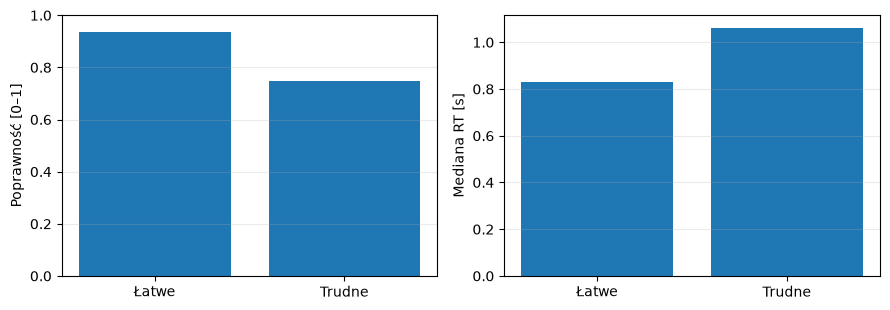

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
nazwy = list(wyniki)
ax[0].bar(nazwy, [wyniki[n][0] for n in nazwy])
ax[0].set(ylabel="Poprawność [0–1]", ylim=(0, 1))
ax[1].bar(nazwy, [wyniki[n][1] for n in nazwy])
ax[1].set(ylabel="Mediana RT [s]")
for panel in ax: panel.grid(axis="y", alpha=.25)
plt.tight_layout(); plt.show()
